In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

In [202]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
model = LogisticRegression(max_iter=1000, class_weight='balanced')
scaler = StandardScaler()

In [203]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [204]:
df['smoking_history'].unique()

array(['never', 'No Info', 'current', 'former', 'ever', 'not current'],
      dtype=object)

In [205]:
df['gender'].unique()

array(['Female', 'Male', 'Other'], dtype=object)

In [206]:
df.dropna()
df['gender'] = df['gender'].map({'Male': 0, 'Female': 1, 'Other': 2})
df['smoking_history'] = df['smoking_history'].map({'never': 0, 'No Info': 1, 'current': 2, 'former': 3, 'ever':4, 'not current':5})
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,1,80.0,0,1,0,25.19,6.6,140,0
1,1,54.0,0,0,1,27.32,6.6,80,0
2,0,28.0,0,0,0,27.32,5.7,158,0
3,1,36.0,0,0,2,23.45,5.0,155,0
4,0,76.0,1,1,2,20.14,4.8,155,0


In [207]:
features = df.columns.drop('diabetes').tolist()
target = ['diabetes'] 

In [208]:
x = df[features]
y = df[target]

In [209]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [210]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [211]:
model.fit(x_train, y_train.values.ravel())

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [212]:
predictions = model.predict(x_test)

In [213]:
cm = confusion_matrix(y_test, predictions)

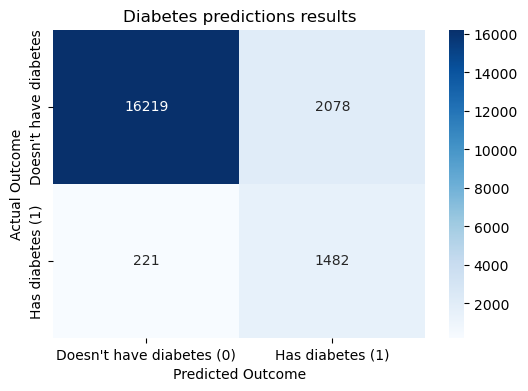

In [214]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Doesn't have diabetes (0)", 'Has diabetes (1)'], 
            yticklabels=["Doesn't have diabetes", 'Has diabetes (1)'])

plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('Diabetes predictions results')
plt.show()